<a href="https://colab.research.google.com/github/mbadiee/Hyperparameter-_-Outlier-Detection/blob/main/Genetic_Algorithm_Homework_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# تمرین سه بخشی الگوریتم ژنتیک با نمایش جایگشتی

این فایل شامل حل مساله هشت وزیر، مرتب‌سازی ۲۰ عدد غیرتکراری و یک مسئله روزمره برنامه‌نویسی است: **تعیین ترتیب اجرای تست‌های نرم‌افزار برای کشف زودتر خطاهای مهم**.

سه Cross Over: **OX، PMX، CX** :و چهار جهش **swap، inversion، insertion، scramble** را در هر سه مسئله مقایسه می‌کنیم.
 داده‌های مرتب‌سازی و تست نرم‌افزار، مثال‌های  ساختگی و بازتولیدپذیر هستند.

## هدف و روش اجرا
 تنظیم پیش‌فرض ۲۰ تکرار برای هر ترکیب و ۷۲۰ اجرای GA در مجموع است؛ زمان اجرا به سخت‌افزار بستگی دارد. خروجی‌های ذخیره‌شده مربوط به اجرای واقعی محلی Python هستند. اجرا در  Colab انجام شد.


## ۱ آماده‌سازی
فقط NumPy، Pandas و Matplotlib برای آزمایش‌ها لازم‌اند و معمولاً از قبل در Colab نصب هستند.

In [ ]:
import importlib.util, subprocess, sys
missing = [name for name in ["numpy", "pandas", "matplotlib"] if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
from IPython.display import display, Image, FileLink
print("Python", sys.version.split()[0])

Python 3.13.18


## ۲ پارامترهای مشترک
هر کروموزوم یک ترتیب کامل از عناصر است. هزینه کمتر بهتر است. انتخاب والدین با تورنمنت سه‌نفره انجام می‌شود و دو عضو برتر مستقیماً وارد نسل بعد می‌شوند. این کار جلوی از دست رفتن بهترین جواب را می‌گیرد.
احتمال Cross Over ۰٫۹ و احتمال جهش ۰٫۲۵ است. احتمال جهش برای هر **کروموزوم فرزند** اعمال می‌شود؛ احتمال مستقل برای تک‌تک ژن‌ها نیست. بودجه پیش‌فرض هر اجرا ۹۶۶۰ ارزیابی است. همه روش‌ها تا نسل آخر ادامه می‌دهند، حتی اگر زودتر به جواب بهینه برسند، تا بودجه‌ها برابر بمانند.

In [ ]:
from __future__ import annotations

import argparse
import itertools
import json
import math
import platform
import random
import time
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


@dataclass
class Config:
    population: int = 60
    generations: int = 160
    crossover_probability: float = 0.90
    mutation_probability: float = 0.25
    elite_count: int = 2
    tournament_size: int = 3
    repeats: int = 20
    base_seed: int = 20261101

CROSSOVERS = ("OX", "PMX", "CX")
MUTATIONS = ("swap", "inversion", "insertion", "scramble")

## ۳ Cross Over و جهش سازگار با جایگشت
OX یک قطعه از والد اول را نگه می‌دارد و بقیه را با ترتیب والد دوم پر می‌کند. PMX  از نگاشت بین دو قطعه برای جلوگیری از تکرار استفاده می‌کند. CX   چرخه‌های موقعیتی والدین را شناسایی می‌کند و چرخه‌ها را یکی‌درمیان از دو والد می‌گیرد.
---
چهار جهش به‌ترتیب جابه‌جایی دو عنصر، معکوس کردن یک قطعه، برداشتن و درج دوباره یک عنصر، و برزدن تصادفی یک قطعه هستند. تمام این عملگرها عناصر اصلی را حفظ می‌کنند.
 Cross Over ساده یک‌نقطه‌ای بدون ترمیم برای این نمایش مناسب نیست، چون ممکن است عدد تکراری تولید کند.

In [ ]:
def crossover(parent1, parent2, method, rng):
    """One permutation-valid child. Segment endpoints are [start, stop)."""
    n = len(parent1)
    if method == "CX":
        child = [-1] * n
        unused = set(range(n))
        location = {v: i for i, v in enumerate(parent1)}
        cycle = 0
        while unused:
            idx = min(unused)
            while idx in unused:
                child[idx] = parent1[idx] if cycle % 2 == 0 else parent2[idx]
                unused.remove(idx)
                idx = location[parent2[idx]]
            cycle += 1
        return child
    start, stop = sorted(rng.sample(range(n + 1), 2))
    child = [-1] * n
    child[start:stop] = parent1[start:stop]
    segment = set(parent1[start:stop])
    if method == "OX":
        remaining = [parent2[i % n] for i in range(stop, stop + n)
                     if parent2[i % n] not in segment]
        free = [i % n for i in range(stop, stop + n)
                if not start <= i % n < stop]
        for idx, value in zip(free, remaining):
            child[idx] = value
    elif method == "PMX":
        location = {v: i for i, v in enumerate(parent1)}
        for idx in itertools.chain(range(start), range(stop, n)):
            value = parent2[idx]
            while value in segment:
                value = parent2[location[value]]
            child[idx] = value
    else:
        raise ValueError(f"Unknown crossover {method}")
    return child


def mutate(chromosome, method, rng):
    """Mutation probability is per chromosome; each operator preserves its items."""
    child = chromosome.copy()
    a, b = sorted(rng.sample(range(len(child)), 2))
    if method == "swap":
        child[a], child[b] = child[b], child[a]
    elif method == "inversion":
        child[a:b + 1] = reversed(child[a:b + 1])
    elif method == "insertion":
        # Either direction is possible; b is interpreted after removal.
        if rng.random() < .5:
            a, b = b, a
        value = child.pop(a)
        child.insert(b, value)
    elif method == "scramble":
        segment = child[a:b + 1]
        rng.shuffle(segment)
        child[a:b + 1] = segment
    else:
        raise ValueError(f"Unknown mutation {method}")
    return child

In [ ]:
demo_parent1 = list(range(8))
demo_parent2 = [3, 6, 1, 0, 7, 4, 2, 5]
print("Parent 1:", demo_parent1, "\nParent 2:", demo_parent2)
for name in CROSSOVERS:
    print(name, crossover(demo_parent1, demo_parent2, name, random.Random(31)))
for name in MUTATIONS:
    print(name, mutate(demo_parent1, name, random.Random(31)))

Parent 1: [0, 1, 2, 3, 4, 5, 6, 7] 
Parent 2: [3, 6, 1, 0, 7, 4, 2, 5]
OX [0, 1, 2, 3, 4, 5, 6, 7]
PMX [0, 1, 2, 3, 4, 5, 6, 7]
CX [0, 6, 1, 3, 4, 5, 2, 7]
swap [3, 1, 2, 0, 4, 5, 6, 7]
inversion [3, 2, 1, 0, 4, 5, 6, 7]
insertion [3, 0, 1, 2, 4, 5, 6, 7]
scramble [2, 3, 1, 0, 4, 5, 6, 7]


## ۴ مدل ریاضی هشت وزیر و مرتب‌سازی
در هشت وزیر، اندیس ژن ستون و مقدار آن شماره سطر است. چون کروموزوم جایگشت ۰ تا ۷ است، تداخل سطر و ستون از ابتدا حذف شده است. تنها حمله‌های قطری را می‌شماریم:
$$ f(q)=\sum_{0\le i<j<8} \mathbf{1}(|q_i-q_j|=j-i). $$

جواب مطلوب هزینه صفر دارد. فضای جست‌وجوی نمایش ما $8!=40320$ است. این مسئله ۹۲ جواب دارد، اگر تقارن‌ها را جدا بشماریم؛ کد این تعداد را مستقلاً با شمارش کامل بررسی می‌کند.
------------
در مرتب‌سازی، خود ۲۰ عدد غیرتکراری ژن‌ها هستند و جابه‌جایی آن‌ها متغیر تصمیم است. هزینه برابر تعداد زوج‌هایی است که ترتیبشان نزولی است:
$$ f(x)=\sum_{i<j}\mathbf{1}(x_i>x_j). $$

کمینه صفر و بیشینه برای ۲۰ عدد برابر ۱۹۰ است. فضای جست‌وجو $20!$ است. استفاده از GA در این بخش برای تمرین و تحلیل نمایش جایگشتی است.

In [ ]:
def queens_cost(population):
    """Each column has one queen. A permutation also prevents row conflicts."""
    x = np.atleast_2d(population)
    i, j = np.triu_indices(x.shape[1], k=1)
    return (np.abs(x[:, i] - x[:, j]) == (j - i)).sum(axis=1).astype(float)


def sorting_cost(population):
    """Number of inverted pairs; zero means ascending order."""
    x = np.atleast_2d(population)
    i, j = np.triu_indices(x.shape[1], k=1)
    return (x[:, i] > x[:, j]).sum(axis=1).astype(float)

## ۵ مسئله کاربردی ترتیب تست‌های نرم‌افزار
فرض کنید یک برنامه‌نویس پس از تغییر کد، ۱۲ تست پروژه را در CI به‌صورت پشت‌سرهم اجرا می‌کند. تست‌ها زمان متفاوتی دارند و هرکدام ممکن است چند نوع خطا را کشف کنند. **تمام تست‌ها اجرا می‌شوند**؛ تصمیم ما فقط ترتیب آن‌هاست. می‌خواهیم خطاهای مهم زودتر کشف شوند.
جدول زمان‌ها، شدت خطاها و پوشش تست‌ها، داده آموزشی فرضی است. در پروژه واقعی باید از زمان اجرا و تاریخچه خطاهای نسخه‌های قبلی استفاده شود، نه از اطلاعات آینده.
اگر $T_j(\pi)$ زمان پایان اولین تستی باشد که خطای $j$ را کشف می‌کند و $w_j$ وزن اهمیت آن خطا باشد، هزینه را این‌طور تعریف می‌کنیم:
$$ f(\pi)=\frac{\sum_j w_jT_j(\pi)}{(\sum_i d_i)(\sum_j w_j)}. $$

این یک معیار تعریف‌شده برای همین تمرین است و نام APFDc را به آن نسبت نمی‌دهیم. هرچه هزینه کمتر باشد، میانگین وزنی زمان کشف خطا کمتر است. کمینه این مسئله الزاماً صفر نیست. هزینه کل اجرای تست‌ها با تغییر ترتیب عوض نمی‌شود. اجرای موازی و وابستگی تست‌ها در این نسخه مدل نشده‌اند.

In [ ]:
def make_ci_data():
    """Illustrative web-project CI suite, not measurements from a real project."""
    names = ["ui_checkout", "login_unit", "payment_integration", "roles_api",
             "orders_api", "input_validation", "db_migration", "cart_unit",
             "search_api", "smoke_health", "invoice_e2e", "token_refresh"]
    seconds = np.array([45, 4, 32, 7, 16, 3, 38, 5, 9, 2, 28, 6], dtype=float)
    faults = ["auth", "permission", "payment", "stock", "validation", "schema",
              "search", "invoice"]
    severity = np.array([9, 10, 10, 8, 6, 9, 5, 7], dtype=float)
    detects = [[0, 2, 3, 4], [0], [2, 7], [0, 1], [1, 3], [4],
               [3, 5], [3, 4], [4, 6], [0, 5], [2, 7], [0, 1]]
    coverage = np.zeros((len(names), len(faults)), dtype=bool)
    for idx, covered in enumerate(detects):
        coverage[idx, covered] = True
    return names, seconds, faults, severity, coverage


def ci_cost(population, seconds, weights, coverage):
    """Weighted completion time of first detecting test / worst-case bound."""
    orders = np.atleast_2d(population).astype(int)
    completion = np.cumsum(seconds[orders], axis=1)
    ordered_coverage = coverage[orders]
    first = np.argmax(ordered_coverage, axis=1)
    detection_time = np.take_along_axis(completion, first, axis=1)
    return (detection_time @ weights) / (seconds.sum() * weights.sum())


def exact_ci_order(seconds, weights, coverage):
    """Subset DP in O(n 2^n). Exact oracle for this small, fixed input only.

    While the next test runs, each undetected fault keeps accruing delay.
    Edge cost = next-test duration * weight of faults still undetected.
    """
    n = len(seconds)
    count = 1 << n
    covered = np.zeros((count, len(weights)), dtype=bool)
    for mask in range(1, count):
        bit = mask & -mask
        idx = bit.bit_length() - 1
        covered[mask] = covered[mask ^ bit] | coverage[idx]
    pending_weight = (~covered) @ weights
    value = np.full(count, np.inf)
    previous = np.full(count, -1, dtype=int)
    picked = np.full(count, -1, dtype=int)
    value[0] = 0.
    for mask in range(count):
        for test in range(n):
            if mask & (1 << test):
                continue
            new_mask = mask | (1 << test)
            candidate = value[mask] + seconds[test] * pending_weight[mask]
            if candidate < value[new_mask]:
                value[new_mask] = candidate
                previous[new_mask] = mask
                picked[new_mask] = test
    order = []
    mask = count - 1
    while mask:
        order.append(int(picked[mask]))
        mask = int(previous[mask])
    order.reverse()
    return order, float(value[-1] / (seconds.sum() * weights.sum()))


def greedy_ci_order(seconds, weights, coverage):
    """Baseline: additional covered severity per second, recomputed each step."""
    pending = set(range(len(seconds)))
    covered = np.zeros(len(weights), dtype=bool)
    order = []
    while pending:
        chosen = max(sorted(pending), key=lambda t:
                     ((coverage[t] & ~covered) @ weights) / seconds[t])
        order.append(chosen)
        pending.remove(chosen)
        covered |= coverage[chosen]
    return order

In [ ]:
test_names, test_seconds, fault_names, fault_weights, coverage = make_ci_data()
display(pd.DataFrame({"test": test_names, "seconds": test_seconds}))
display(pd.DataFrame(coverage.astype(int), index=test_names, columns=fault_names))
print("Total suite seconds:", test_seconds.sum())
oracle_order, oracle_cost = exact_ci_order(test_seconds, fault_weights, coverage)
print("Exact optimum cost:", oracle_cost)
print("Exact optimum order:", [test_names[i] for i in oracle_order])

,test,seconds
0,ui_checkout,45.0
1,login_unit,4.0
2,payment_integration,32.0
3,roles_api,7.0
4,orders_api,16.0
5,input_validation,3.0
6,db_migration,38.0
7,cart_unit,5.0
8,search_api,9.0
9,smoke_health,2.0


,auth,permission,payment,stock,validation,schema,search,invoice
ui_checkout,1,0,1,1,1,0,0,0
login_unit,1,0,0,0,0,0,0,0
payment_integration,0,0,1,0,0,0,0,1
roles_api,1,1,0,0,0,0,0,0
orders_api,0,1,0,1,0,0,0,0
input_validation,0,0,0,0,1,0,0,0
db_migration,0,0,0,1,0,1,0,0
cart_unit,0,0,0,1,1,0,0,0
search_api,0,0,0,0,1,0,1,0
smoke_health,1,0,0,0,0,1,0,0


Total suite seconds: 195.0
Exact optimum cost: 0.09703525641025641
Exact optimum order: ['smoke_health', 'cart_unit', 'token_refresh', 'invoice_e2e', 'search_api', 'ui_checkout', 'login_unit', 'payment_integration', 'roles_api', 'orders_api', 'input_validation', 'db_migration']


## ۶ هسته مشترک الگوریتم ژنتیک
ابتدا جمعیت تصادفی می‌سازیم و هزینه هر عضو را حساب می‌کنیم. در هر نسل، دو عضو برتر را نگه می‌داریم؛ برای بقیه جمعیت والد انتخاب می‌کنیم، Cross Over و جهش را با احتمال مشخص اعمال می‌کنیم و هزینه نسل جدید را می‌سنجیم. معیار انتخاب، **کمترین هزینه** است.
در تکرار هم‌شماره، جمعیت اولیه برای همه ترکیب‌های عملگر یکسان است. جریان تصادفی تکامل روش‌ها جداست. نسل رسیدن به جواب بهینه ثبت می‌شود و در اجرای ناموفق مقدار آن خالی می‌ماند.

In [ ]:
def run_ga(items, objective, crossover_name, mutation_name, config, seed, target):
    """Minimization GA. Every method receives the same evaluation budget."""
    initial_rng = random.Random(seed)
    method_index = CROSSOVERS.index(crossover_name) * len(MUTATIONS) + MUTATIONS.index(mutation_name)
    rng = random.Random(seed + 100000 * (method_index + 1))
    population = [initial_rng.sample(list(items), len(items)) for _ in range(config.population)]
    costs = objective(np.asarray(population))
    best_history = [float(costs.min())]
    hit_generation = 0 if best_history[-1] <= target + 1e-12 else None
    start = time.perf_counter()
    for generation in range(1, config.generations + 1):
        elite_idx = np.argsort(costs, kind="stable")[:config.elite_count]
        next_population = [population[i].copy() for i in elite_idx]

        def select():
            candidates = rng.sample(range(config.population), config.tournament_size)
            winner = min(candidates, key=lambda k: costs[k])
            return population[winner]

        while len(next_population) < config.population:
            p1, p2 = select(), select()
            child = (crossover(p1, p2, crossover_name, rng)
                     if rng.random() < config.crossover_probability else p1.copy())
            if rng.random() < config.mutation_probability:
                child = mutate(child, mutation_name, rng)
            next_population.append(child)
        population = next_population
        costs = objective(np.asarray(population))
        best_history.append(float(costs.min()))
        if hit_generation is None and best_history[-1] <= target + 1e-12:
            hit_generation = generation
    index = int(np.argmin(costs))
    return {
        "best_cost": float(costs[index]),
        "best_solution": list(map(int, population[index])),
        "success": bool(costs[index] <= target + 1e-12),
        "hit_generation": hit_generation,
        "seconds": time.perf_counter() - start,
        "evaluations": config.population * (config.generations + 1),
        "history": best_history,
    }

## ۷ کنترل درستی پیاده‌سازی
عملگرها را روی هزاران والد تصادفی بررسی می‌کنیم تا عنصر تکراری یا حذف‌شده تولید نکنند. تابع هشت وزیر با یک جواب معتبر و حالت تماماً قطری بررسی می‌شود. تعداد ۹۲ جواب نیز با شمارش کامل کنترل می‌شود. برای مسئله تست‌ها، برنامه‌ریزی پویا روی ۱۲ تست، مرجع دقیق می‌دهد؛ صحت خود آن را برای مسئله کوچک‌تر شش‌تستی با شمارش همه ترتیب‌ها مقایسه می‌کنیم.

In [ ]:
def verify_implementation():
    """Meaningful checks for validity, objective correctness and exact oracle."""
    rng = random.Random(17)
    checks = 0
    for n in [8, 12, 20]:
        for _ in range(200):
            p1, p2 = rng.sample(range(n), n), rng.sample(range(n), n)
            for method in CROSSOVERS:
                child = crossover(p1, p2, method, rng)
                assert sorted(child) == list(range(n))
                checks += 1
            for method in MUTATIONS:
                child = mutate(p1, method, rng)
                assert sorted(child) == list(range(n))
                assert sorted(p1) == list(range(n))
                checks += 1
    known_queen = [0, 4, 7, 5, 2, 6, 1, 3]
    assert queens_cost([known_queen])[0] == 0
    assert queens_cost([list(range(8))])[0] == 28
    assert sorting_cost([list(range(20))])[0] == 0
    assert sorting_cost([list(range(19, -1, -1))])[0] == 190
    all_queens = np.array(list(itertools.permutations(range(8))))
    assert int((queens_cost(all_queens) == 0).sum()) == 92
    _, seconds, _, weights, coverage = make_ci_data()
    order, optimum = exact_ci_order(seconds, weights, coverage)
    assert abs(ci_cost([order], seconds, weights, coverage)[0] - optimum) < 1e-12
    # An independent brute-force oracle for the first six tests and their faults.
    small_coverage = coverage[:6]
    detectable = small_coverage.any(axis=0)
    small_coverage = small_coverage[:, detectable]
    small_weights = weights[detectable]
    brute = min(ci_cost(np.array(list(itertools.permutations(range(6)))),
                        seconds[:6], small_weights, small_coverage))
    _, dp = exact_ci_order(seconds[:6], small_weights, small_coverage)
    assert abs(brute - dp) < 1e-12
    return {"operator_validity_checks": checks, "queens_exact_solutions": 92,
            "objective_and_dp_checks": "passed", "ci_exact_optimum": optimum}

In [ ]:
checks = verify_implementation()
display(checks)

{'operator_validity_checks': 4200,
 'queens_exact_solutions': 92,
 'objective_and_dp_checks': 'passed',
 'ci_exact_optimum': 0.09703525641025641}

## ۸ اجرای آزمایش‌ها
برای هر مسئله، ۱۲ ترکیب Cross Over و جهش و برای هر ترکیب ۲۰ تکرار انجام می‌دهیم. مقایسه بر پایه هزینه نهایی، انحراف معیار نمونه‌ای، نرخ رسیدن به بهینه و نسل اولین موفقیت است. زمان ثبت می‌شود اما بین سخت‌افزارها قابل مقایسه مستقیم نیست.
برای تست سریع می‌توان پایین `repeats=3, generations=40` قرار دهید؛ نتایج گزارش Word با تنظیم کامل `repeats=20, generations=160` محاسبه شده‌اند. تعداد نسل و نرخ جهش را در آزمایش اصلی ثابت نگه داشته‌ایم. از این مقایسه، برتری همیشگی هیچ عملگری را نتیجه نمی‌گیریم.

In [ ]:
def summarize(frame):
    return frame.groupby(['problem','crossover','mutation'],as_index=False).agg(
        mean_cost=('best_cost','mean'),std_cost=('best_cost','std'),
        best_cost=('best_cost','min'),worst_cost=('best_cost','max'),
        success_rate=('success','mean'),
        median_hit_generation_successes=('hit_generation','median'),
        mean_seconds=('seconds','mean'),runs=('run','count'))


def make_plots(frame, histories, best, problems, output):
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                         "axes.spines.top": False, "axes.spines.right": False,
                         "figure.dpi": 120})
    for problem, _, _, _ in problems:
        selected = frame[frame.problem == problem]
        aggregate = summarize(selected)
        pivot = aggregate.pivot(index="crossover", columns="mutation", values="success_rate").reindex(index=CROSSOVERS, columns=MUTATIONS)
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
        image = axes[0].imshow(pivot.values, vmin=0, vmax=1, cmap="Blues", aspect="auto")
        axes[0].set_xticks(range(4), MUTATIONS, rotation=20)
        axes[0].set_yticks(range(3), CROSSOVERS)
        axes[0].set_title(f"{problem}: optimum hit rate ({int(selected.run.max())+1} runs)")
        for i in range(3):
            for j in range(4):
                axes[0].text(j, i, f"{pivot.values[i,j]:.0%}",ha="center",va="center",
                             color="white" if pivot.values[i,j] > .6 else "black")
        fig.colorbar(image, ax=axes[0], label="Fraction of runs reaching known optimum")
        for cross in CROSSOVERS:
            for mutation in MUTATIONS:
                curves = [h['history'] for h in histories if h['problem'] == problem
                          and h['crossover'] == cross and h['mutation'] == mutation]
                axes[1].plot(np.mean(curves, axis=0), label=f"{cross}/{mutation}", lw=1.1)
        axes[1].set(xlabel="Generation", ylabel="Mean best cost (lower is better)",title="Convergence under the same budget")
        axes[1].legend(fontsize=6, ncol=2)
        fig.tight_layout()
        fig.savefig(output / f"{problem}_comparison.png", bbox_inches="tight")
        plt.close(fig)

    # The board is a visualization of the returned solution, not an illustration.
    queen = best['queens']['best_solution']
    fig, ax = plt.subplots(figsize=(4.3, 4.3))
    board = np.indices((8, 8)).sum(axis=0) % 2
    ax.imshow(board, cmap="Pastel1", origin="lower", vmin=0, vmax=1)
    ax.scatter(range(8), queen, marker="*",s=520,color="#153a59",edgecolor="white")
    ax.set(xticks=range(8),yticks=range(8),xlabel="Column",ylabel="Row",
           title=f"Returned 8-queens board: {best['queens']['best_cost']:.0f} attacking pairs")
    fig.tight_layout(); fig.savefig(output/'queens_solution.png'); plt.close(fig)

    _, seconds, faults, weights, coverage = make_ci_data()
    order = best['ci_tests']['best_solution']
    completion = seconds[order].cumsum()
    first = coverage[order].argmax(axis=0)
    discovery = completion[first]
    fig, ax = plt.subplots(figsize=(7.4, 3.5))
    ax.barh(faults, discovery, color="#286e8d")
    ax.set(xlabel="Seconds until first detection", title="CI test ordering: when each fault is discovered")
    for i, value in enumerate(discovery): ax.text(value+.4,i,f"{value:.0f}s",va="center",fontsize=8)
    fig.tight_layout();fig.savefig(output/'ci_fault_detection.png',bbox_inches="tight");plt.close(fig)


def run_all(output='results', config=None):
    config = config or Config()
    assert config.population >= config.tournament_size
    assert 1 <= config.elite_count < config.population
    assert config.generations >= 1 and config.repeats >= 2
    assert 0 <= config.crossover_probability <= 1 and 0 <= config.mutation_probability <= 1
    output = Path(output);output.mkdir(parents=True,exist_ok=True)
    checks = verify_implementation()
    numbers = random.Random(config.base_seed + 9000).sample(range(5,101),20)
    names, seconds, faults, weights, coverage = make_ci_data()
    optimum_order, optimum = exact_ci_order(seconds, weights, coverage)
    ci_objective = lambda pop: ci_cost(pop, seconds, weights, coverage)
    problems = [('queens',list(range(8)),queens_cost,0.),
                ('sorting',numbers,sorting_cost,0.),
                ('ci_tests',list(range(len(names))),ci_objective,optimum)]
    rows, histories, best = [], [], {}
    for problem_number, (problem, items, objective, target) in enumerate(problems):
        print(f'Running {problem}: {len(CROSSOVERS)*len(MUTATIONS)} combinations x {config.repeats} runs',flush=True)
        for cross in CROSSOVERS:
            for mutation in MUTATIONS:
                for run in range(config.repeats):
                    seed = config.base_seed + 10000 * problem_number + run
                    result = run_ga(items,objective,cross,mutation,config,seed,target)
                    assert sorted(result['best_solution']) == sorted(items)
                    assert np.all(np.diff(result['history']) <= 1e-12)
                    # Recompute the objective from the actual returned solution.
                    assert abs(objective([result['best_solution']])[0]-result['best_cost']) < 1e-12
                    assert result['best_cost'] >= target - 1e-12
                    row = {"problem":problem,"crossover":cross,"mutation":mutation,
                           "run":run,"seed":seed,**{k:v for k,v in result.items() if k not in ['history','best_solution']}}
                    rows.append(row)
                    histories.append({"problem":problem,"crossover":cross,"mutation":mutation,
                                      "run":run,"history":result['history']})
                    if problem not in best or result['best_cost'] < best[problem]['best_cost']:
                        best[problem]={**row,'best_solution':result['best_solution']}
        print(f'  Best returned objective = {best[problem]["best_cost"]:.8f}',flush=True)
    frame=pd.DataFrame(rows)
    aggregate=summarize(frame)
    frame.to_csv(output/'runs.csv',index=False)
    aggregate.to_csv(output/'summary.csv',index=False)
    baseline_orders = {'current_order':list(range(len(names))),
                       'shortest_first':np.argsort(seconds,kind='stable').tolist(),
                       'greedy_coverage_per_second':greedy_ci_order(seconds,weights,coverage),
                       'exact_subset_dp':optimum_order,
                       'best_ga':best['ci_tests']['best_solution']}
    baselines = [{'method':k,'cost':float(ci_objective([v])[0]),
                  'weighted_detection_seconds':float(ci_objective([v])[0]*seconds.sum()),
                  'order':v,'test_names':[names[t] for t in v]}
                 for k,v in baseline_orders.items()]
    # Save every input needed to reproduce, not only seeds.
    inputs={'sorting_input':numbers,'ci_test_names':names,'ci_durations_seconds':seconds.tolist(),
            'ci_fault_names':faults,'ci_severity_weights':weights.tolist(),
            'ci_coverage_matrix':coverage.astype(int).tolist(),
            'input_provenance':'Synthetic teaching scenario, not production observations'}
    metadata={'config':asdict(config),'python':platform.python_version(),
              'numpy':np.__version__,'pandas':pd.__version__,
              'execution_environment':'local Python; Colab-compatible but not executed on Colab here',
              'checks':checks,'inputs':inputs,'best_solutions':best,'ci_baselines':baselines,
              'ci_exact_optimum':optimum,'total_runs':len(frame),
              'evaluations_per_run':config.population*(config.generations+1)}
    for filename, data in [('results.json',metadata),('histories.json',histories),('input_data.json',inputs)]:
        (output/filename).write_text(json.dumps(data,indent=2,ensure_ascii=False),encoding='utf-8')
    pd.DataFrame(baselines).to_csv(output/'ci_baselines.csv',index=False)
    pd.DataFrame({'test_name':names,'duration_seconds':seconds}).to_csv(output/'ci_tests.csv',index=False)
    pd.DataFrame(coverage.astype(int),index=names,columns=faults).to_csv(output/'ci_coverage.csv')
    make_plots(frame,histories,best,problems,output)
    print(aggregate.to_string(index=False),flush=True)
    return frame,aggregate,metadata

In [ ]:
CONFIG = Config(repeats=20, generations=160)
OUTPUT_DIR = Path("results")
runs, summary, metadata = run_all(OUTPUT_DIR, CONFIG)
print("Total GA runs:", metadata["total_runs"])
print("Evaluations per GA run:", metadata["evaluations_per_run"])

Running queens: 12 combinations x 20 runs
  Best returned objective = 0.00000000
Running sorting: 12 combinations x 20 runs
  Best returned objective = 0.00000000
Running ci_tests: 12 combinations x 20 runs
  Best returned objective = 0.09703526
 problem crossover  mutation  mean_cost  std_cost  best_cost  worst_cost  success_rate  median_hit_generation_successes  mean_seconds  runs
ci_tests        CX insertion   0.097676  0.001139   0.097035    0.099599          0.75                             13.0      0.242107    20
ci_tests        CX inversion   0.097163  0.000573   0.097035    0.099599          0.95                             17.0      0.177564    20
ci_tests        CX  scramble   0.097035  0.000000   0.097035    0.097035          1.00                             14.0      0.192545    20
ci_tests        CX      swap   0.097035  0.000000   0.097035    0.097035          1.00                             16.0      0.176923    20
ci_tests        OX insertion   0.097676  0.001139   0.

## ۹ نتیجه هشت وزیر
نرخ موفقیت، سهم اجراهایی است که واقعاً هزینه صفر پیدا کرده‌اند. منحنی سمت راست میانگین بهترین هزینه در هر نسل را نشان می‌دهد. یک جواب موفق به معنی موفقیت تمام تکرارها نیست. شکل صفحه شطرنج دقیقاً از کروموزوم خروجی رسم شده است.

,problem,crossover,mutation,mean_cost,std_cost,best_cost,worst_cost,success_rate,median_hit_generation_successes,mean_seconds,runs
12,queens,CX,insertion,0.00,0.00000,0.0,0.0,1.00,3.0,0.22567,20
13,queens,CX,inversion,0.00,0.00000,0.0,0.0,1.00,3.5,0.15304,20
14,queens,CX,scramble,0.00,0.00000,0.0,0.0,1.00,5.0,0.15781,20
15,queens,CX,swap,0.00,0.00000,0.0,0.0,1.00,4.0,0.15065,20
16,queens,OX,insertion,0.00,0.00000,0.0,0.0,1.00,3.0,0.25540,20
17,queens,OX,inversion,0.00,0.00000,0.0,0.0,1.00,4.0,0.43767,20
18,queens,OX,scramble,0.00,0.00000,0.0,0.0,1.00,4.5,0.20133,20
19,queens,OX,swap,0.00,0.00000,0.0,0.0,1.00,2.0,0.28104,20
20,queens,PMX,insertion,0.00,0.00000,0.0,0.0,1.00,3.5,0.22849,20
21,queens,PMX,inversion,0.00,0.00000,0.0,0.0,1.00,3.0,0.15709,20


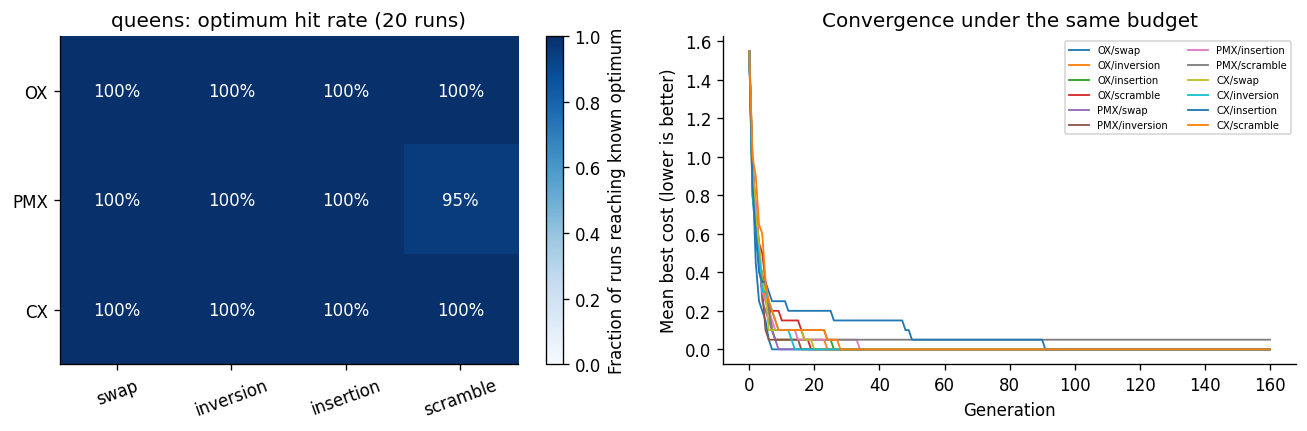

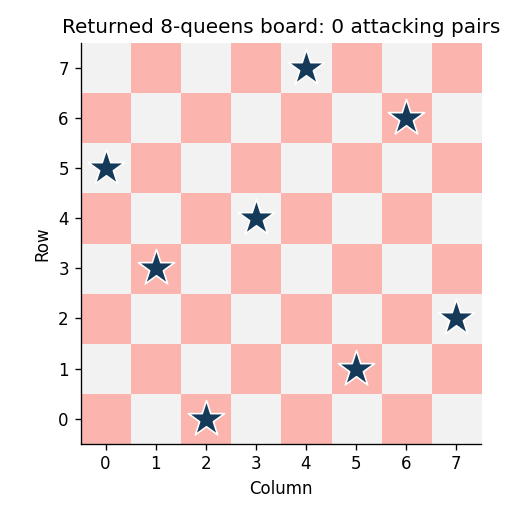

Returned solution: [5, 3, 0, 4, 7, 1, 6, 2]


In [ ]:
display(summary[summary.problem == "queens"].round(5))
display(Image(filename=str(OUTPUT_DIR / "queens_comparison.png")))
display(Image(filename=str(OUTPUT_DIR / "queens_solution.png")))
print("Returned solution:", metadata["best_solutions"]["queens"]["best_solution"])

## ۱۰ نتیجه مرتب‌سازی
تمام روش‌ها همان ۲۰ عدد را دریافت می‌کنند. تفاوت فقط در ترتیب جست‌وجو و عملگرهاست. عددهای تکراری به مسئله وارد نکرده‌ایم. اگر هزینه صفر شود، ترتیب خروجی باید دقیقاً برابر خروجی تابع معمول `sorted` باشد.

Input: [73, 36, 88, 67, 90, 5, 34, 50, 84, 19, 38, 66, 62, 81, 64, 27, 24, 20, 44, 12]
Best GA output: [5, 12, 19, 20, 24, 27, 34, 36, 38, 44, 50, 62, 64, 66, 67, 73, 81, 84, 88, 90]
Matches Python sorted: True


,problem,crossover,mutation,mean_cost,std_cost,best_cost,worst_cost,success_rate,median_hit_generation_successes,mean_seconds,runs
24,sorting,CX,insertion,0.00,0.00000,0.0,0.0,1.00,60.0,0.31241,20
25,sorting,CX,inversion,0.00,0.00000,0.0,0.0,1.00,75.0,0.27680,20
26,sorting,CX,scramble,0.00,0.00000,0.0,0.0,1.00,71.0,0.26680,20
27,sorting,CX,swap,0.00,0.00000,0.0,0.0,1.00,71.5,0.25543,20
28,sorting,OX,insertion,0.00,0.00000,0.0,0.0,1.00,70.0,0.20404,20
29,sorting,OX,inversion,0.05,0.22361,0.0,1.0,0.95,90.0,0.27804,20
30,sorting,OX,scramble,0.00,0.00000,0.0,0.0,1.00,80.0,0.21171,20
31,sorting,OX,swap,0.00,0.00000,0.0,0.0,1.00,81.5,0.23389,20
32,sorting,PMX,insertion,0.00,0.00000,0.0,0.0,1.00,46.0,0.18881,20
33,sorting,PMX,inversion,0.00,0.00000,0.0,0.0,1.00,80.5,0.19191,20


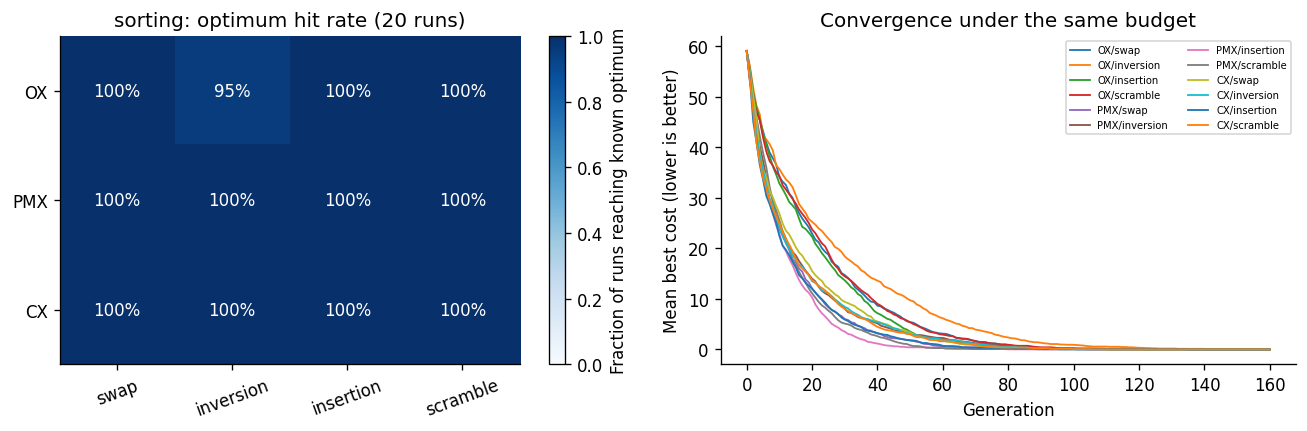

In [ ]:
print("Input:", metadata["inputs"]["sorting_input"])
sorting_solution = metadata["best_solutions"]["sorting"]["best_solution"]
print("Best GA output:", sorting_solution)
print("Matches Python sorted:", sorting_solution == sorted(metadata["inputs"]["sorting_input"]))
display(summary[summary.problem == "sorting"].round(5))
display(Image(filename=str(OUTPUT_DIR / "sorting_comparison.png")))

## ۱۱ نتیجه ترتیب تست‌های نرم‌افزار
چهار مرجع برای مقایسه داریم: ترتیب فعلی فرضی، تست‌های کوتاه‌تر در ابتدا، روش حریصانه پوشش اهمیت جدید بر زمان، و جواب دقیق برنامه‌ریزی پویا. روش حریصانه تضمین بهینگی عمومی ندارد؛ برنامه‌ریزی پویا برای همین نمونه کوچک مرجع دقیق است.
در نمودار زمان کشف، پایان اولین تست کشف‌کننده هر خطا رسم می‌شود. فاصله تا مرجع دقیق را می‌توان محاسبه کرد؛ برای GA نیز نرخ موفقیت یعنی سهم رسیدن به همان هزینه بهینه، حتی اگر ترتیب بهینه دیگری پیدا کند.

,method,cost,weighted_detection_seconds
0,current_order,0.403205,78.625000
1,shortest_first,0.153686,29.968750
2,greedy_coverage_per_second,0.097035,18.921875
3,exact_subset_dp,0.097035,18.921875
4,best_ga,0.097035,18.921875


,problem,crossover,mutation,mean_cost,std_cost,best_cost,worst_cost,success_rate,median_hit_generation_successes,mean_seconds,runs
0,ci_tests,CX,insertion,0.097676,0.001139,0.097035,0.099599,0.75,13.0,0.242107,20
1,ci_tests,CX,inversion,0.097163,0.000573,0.097035,0.099599,0.95,17.0,0.177564,20
2,ci_tests,CX,scramble,0.097035,0.000000,0.097035,0.097035,1.00,14.0,0.192545,20
3,ci_tests,CX,swap,0.097035,0.000000,0.097035,0.097035,1.00,16.0,0.176923,20
4,ci_tests,OX,insertion,0.097676,0.001139,0.097035,0.099599,0.75,13.0,0.176455,20
5,ci_tests,OX,inversion,0.097676,0.001139,0.097035,0.099599,0.75,21.0,0.178103,20
6,ci_tests,OX,scramble,0.097420,0.000939,0.097035,0.099599,0.85,17.0,0.230066,20
7,ci_tests,OX,swap,0.097035,0.000000,0.097035,0.097035,1.00,19.0,0.249773,20
8,ci_tests,PMX,insertion,0.097163,0.000573,0.097035,0.099599,0.95,11.0,0.168392,20
9,ci_tests,PMX,inversion,0.097035,0.000000,0.097035,0.097035,1.00,14.5,0.169670,20


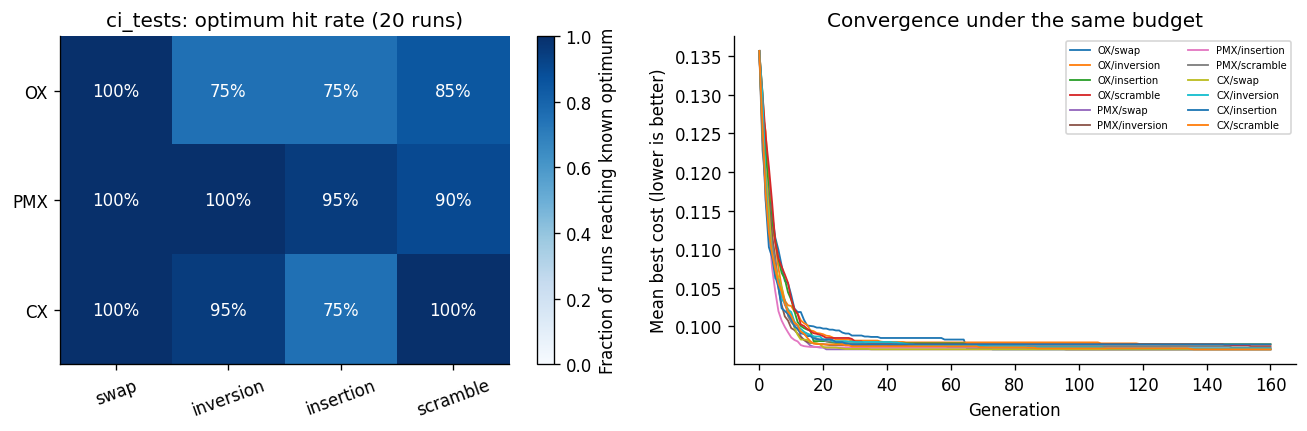

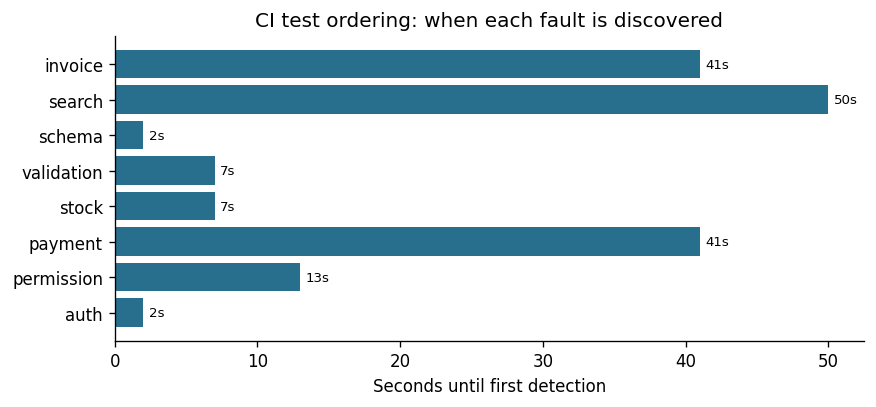

Best GA test order: ['smoke_health', 'cart_unit', 'token_refresh', 'invoice_e2e', 'search_api', 'input_validation', 'payment_integration', 'db_migration', 'ui_checkout', 'login_unit', 'roles_api', 'orders_api']
Reduction in weighted detection delay vs illustrative current order (%): 75.93402225755167
Reduction in total suite duration: 0%; all tests still run.


In [ ]:
baseline_table = pd.DataFrame(metadata["ci_baselines"])
display(baseline_table[["method", "cost", "weighted_detection_seconds"]].round(6))
display(summary[summary.problem == "ci_tests"].round(6))
display(Image(filename=str(OUTPUT_DIR / "ci_tests_comparison.png")))
display(Image(filename=str(OUTPUT_DIR / "ci_fault_detection.png")))
print("Best GA test order:", metadata["ci_baselines"][-1]["test_names"])
current = metadata["ci_baselines"][0]["cost"]
ga_cost = metadata["ci_baselines"][-1]["cost"]
print("Reduction in weighted detection delay vs illustrative current order (%):", 100*(current-ga_cost)/current)
print("Reduction in total suite duration: 0%; all tests still run.")


## ۱۲ جمع‌بندی و محدودیت‌ها
جدول زیر نتیجه واقعی همین اجرا را خلاصه می‌کند. هر سه مسئله نمایش جایگشتی دارند، اما تابع هدف آن‌ها متفاوت است. انتخاب عملگر مناسب باید بر اساس چند تکرار و مسئله موردنظر انجام شود. مقایسه حاضر توصیفی است و ادعای برتری آماری فراگیر ندارد. داده‌های مسئله تست‌ها فرضی هستند؛ برای کاربرد واقعی باید روی چند پروژه و نسخه مستقل بررسی شوند.

In [ ]:
for problem in ["queens", "sorting", "ci_tests"]:
    part = runs[runs.problem == problem]
    print(problem, "best =", part.best_cost.min(), "successful runs =", int(part.success.sum()), "/", len(part))
assert len(runs) == 3 * len(CROSSOVERS) * len(MUTATIONS) * CONFIG.repeats
assert runs.evaluations.nunique() == 1
assert not runs.best_cost.isna().any()
print("All experiment-output checks passed.")

queens best = 0.0 successful runs = 239 / 240
sorting best = 0.0 successful runs = 239 / 240
ci_tests best = 0.09703525641025641 successful runs = 218 / 240
All experiment-output checks passed.


سلول زیر پوشه خروجی‌ها را فشرده می‌کند.

In [ ]:
import shutil
archive_path = shutil.make_archive("GA_Homework_Results", "zip", OUTPUT_DIR)
display(FileLink(archive_path))
# Optional, run manually in Colab to start the browser download:
# from google.colab import files
# files.download(archive_path)

/content/GA_Homework_Results.zip